A análise se baseará em order_reviews para descobrir os motivos principais das notas abaixo de 3 estrelas

In [40]:
import matplotlib.pyplot as plt
import pandas as pd

order_payments = pd.read_csv("../archive/olist_order_payments_dataset.csv")
order_itens = pd.read_csv("../archive/olist_order_items_dataset.csv")
order_reviews = pd.read_csv("../archive/olist_order_reviews_dataset.csv")
sellers = pd.read_csv("../archive/olist_sellers_dataset.csv")
products = pd.read_csv("../archive/olist_products_dataset.csv")
orders = pd.read_csv("../archive/olist_orders_dataset.csv")
customers = pd.read_csv("../archive/olist_customers_dataset.csv")

Análises iniciais das notas baixas

nulos em review_score: 0


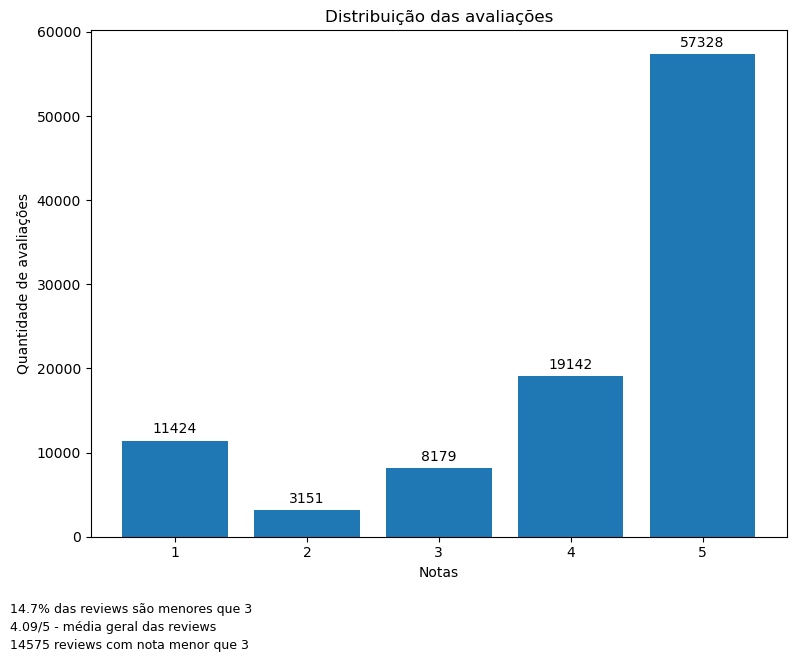

In [41]:
# checando se existem valores nulos no campo de review_score (não existem)
print("nulos em review_score:", order_reviews["review_score"].isnull().sum())

order_reviews_menor_q_3 = order_reviews.loc[order_reviews["review_score"] < 3]
porcentagem_menor_que_3 = len(order_reviews_menor_q_3) / len(order_reviews) * 100
media_order_reviews_geral = float(order_reviews["review_score"].mean())

notas = order_reviews["review_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(notas.index, notas.values)
ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_title("Distribuição das avaliações")
ax.set_xlabel("Notas")
ax.set_ylabel("Quantidade de avaliações")
ax.set_xticks([1, 2, 3, 4, 5])
plt.figtext(0.01, -0.03, f"{porcentagem_menor_que_3:.1f}% das reviews são menores que 3", fontsize=9, color="black")
plt.figtext(0.01, -0.06, f"{media_order_reviews_geral:.2f}/5 - média geral das reviews", fontsize=9, color="black")
plt.figtext(0.01, -0.09, f"{len(order_reviews_menor_q_3)} reviews com nota menor que 3", fontsize=9, color="black")
plt.tight_layout()
plt.show()

### Granularidade da análise

A análise é feita em cima das reviews, então a tabela final tem **1 linha por review**.

Um mesmo pedido pode ter vários itens e vários pagamentos. Se juntarmos as tabelas direto, a review se repete
uma vez para cada item/pagamento. Por isso, itens e pagamentos são **agregados por pedido antes do merge**:
- valores de produtos e frete são somados
- `order_full_price` é a soma de todos os pagamentos do pedido
- categoria e vendedor são os do item mais caro do pedido

In [42]:
# Itens: 1 linha por pedido.
# Ordenando pelo preço para que categoria/vendedor sejam os do item mais caro do pedido.
itens_com_info = (
    order_itens
    .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(sellers[["seller_id", "seller_city", "seller_state"]], on="seller_id", how="left")
    .sort_values(["order_id", "price"], ascending=[True, False])
)

itens_por_pedido = itens_com_info.groupby("order_id", as_index=False).agg(
    qtd_itens=("order_item_id", "count"),
    qtd_vendedores=("seller_id", "nunique"),
    valor_produtos=("price", "sum"),
    valor_frete=("freight_value", "sum"),
    product_category_name=("product_category_name", "first"),
    seller_id=("seller_id", "first"),
    seller_city=("seller_city", "first"),
    seller_state=("seller_state", "first"),
)

# Pagamentos: 1 linha por pedido (um pedido pode ser pago com voucher + cartão, por exemplo).
# O tipo de pagamento considerado é o de maior valor.
pagamentos_por_pedido = (
    order_payments
    .sort_values(["order_id", "payment_value"], ascending=[True, False])
    .groupby("order_id", as_index=False)
    .agg(
        order_full_price=("payment_value", "sum"),
        payment_type=("payment_type", "first"),
        payment_installments=("payment_installments", "max"),
        qtd_pagamentos=("payment_sequential", "count"),
    )
)

print("pedidos com mais de 1 item:", (itens_por_pedido["qtd_itens"] > 1).sum())
print("pedidos com mais de 1 pagamento:", (pagamentos_por_pedido["qtd_pagamentos"] > 1).sum())

pedidos com mais de 1 item: 9803
pedidos com mais de 1 pagamento: 2961


Gerando uma tabela com todas as reviews (1 linha por review) unindo os dados das outras tabelas

In [43]:
order_reviews_all = (
    order_reviews[["review_id", "order_id", "review_score", "review_comment_title", "review_comment_message",
                   "review_creation_date", "review_answer_timestamp"]]
    .merge(itens_por_pedido, on="order_id", how="left")
    .merge(pagamentos_por_pedido, on="order_id", how="left")
    .merge(
        orders[["order_id", "customer_id", "order_status", "order_purchase_timestamp", "order_approved_at",
                "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]],
        on="order_id",
        how="left",
    )
    .merge(customers[["customer_id", "customer_city", "customer_state"]], on="customer_id", how="left")
)

# Removendo apenas linhas realmente repetidas (mesma review do mesmo pedido).
# Um pedido pode ter mais de uma review, e as duas devem ser mantidas.
order_reviews_all = order_reviews_all.drop_duplicates(subset=["review_id", "order_id"])

for coluna in ["review_creation_date", "review_answer_timestamp", "order_purchase_timestamp", "order_approved_at",
               "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    order_reviews_all[coluna] = pd.to_datetime(order_reviews_all[coluna])

for coluna in ["qtd_itens", "qtd_vendedores", "qtd_pagamentos", "payment_installments"]:
    order_reviews_all[coluna] = order_reviews_all[coluna].astype("Int64")

# Atraso em dias, comparando só a data (a data estimada sempre vem com hora 00:00,
# então um pedido entregue no próprio dia previsto conta como entregue no prazo).
order_reviews_all["delivery_delay_days"] = (
    order_reviews_all["order_delivered_customer_date"].dt.normalize()
    - order_reviews_all["order_estimated_delivery_date"]
).dt.days
# Pedidos não entregues ficam com entrega_atrasada vazio (NA), e não como False
order_reviews_all["entrega_atrasada"] = (
    (order_reviews_all["delivery_delay_days"] > 0)
    .astype("boolean")
    .mask(order_reviews_all["delivery_delay_days"].isna())
)

print("linhas (1 por review):", len(order_reviews_all))
order_reviews_all.to_csv("created-tables/order_reviews_all.csv", index=False)

linhas (1 por review): 99224


Gerando as tabelas de reclamações (nota menor que 3)

In [44]:
# Todas as reviews com nota menor que 3 (com ou sem comentário), incluindo pedidos não entregues.
order_reviews_complaints_full_data = order_reviews_all.loc[order_reviews_all["review_score"] < 3].copy()
order_reviews_complaints_full_data.to_csv("created-tables/order_reviews_complaints_full_data.csv", index=False)

# Versão simplificada: só pedidos entregues e com itens, com as colunas usadas na análise.
order_reviews_complaints_simplified = (
    order_reviews_complaints_full_data
    .dropna(subset=["valor_produtos", "order_delivered_customer_date"])
    [[
        "review_id",
        "order_id",
        "review_score",
        "review_comment_message",
        "product_category_name",
        "seller_state",
        "qtd_itens",
        "valor_produtos",
        "valor_frete",
        "order_full_price",
        "payment_type",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days",
        "entrega_atrasada",
    ]]
)
order_reviews_complaints_simplified.to_csv("created-tables/order_reviews_complaints_simplified.csv", index=False)

print("reclamações (todas):", len(order_reviews_complaints_full_data))
print("reclamações de pedidos entregues:", len(order_reviews_complaints_simplified))

reclamações (todas): 14575
reclamações de pedidos entregues: 12350


### Porcentagem de entregas dentro do prazo

Considerando apenas pedidos entregues. Um pedido é **atrasado** quando a data de entrega é posterior à data estimada.

In [45]:
entregues = order_reviews_all.dropna(subset=["order_delivered_customer_date", "order_estimated_delivery_date"])
notas_ruins = entregues.loc[entregues["review_score"] < 3]
notas_boas = entregues.loc[entregues["review_score"] >= 3]

porcentagem_no_prazo_notas_ruins = float((~notas_ruins["entrega_atrasada"]).mean() * 100)
porcentagem_no_prazo_notas_boas = float((~notas_boas["entrega_atrasada"]).mean() * 100)

print(f"entregas no prazo - notas ruins (< 3): {porcentagem_no_prazo_notas_ruins:.2f}%")
print(f"entregas no prazo - notas boas (>= 3): {porcentagem_no_prazo_notas_boas:.2f}%")

entregas no prazo - notas ruins (< 3): 67.61%
entregas no prazo - notas boas (>= 3): 97.13%


In [46]:
# Porcentagem de pedidos atrasados em cada nota
atraso_por_nota = (
    entregues.groupby("review_score")
    .agg(
        qtd_reviews=("review_id", "count"),
        porcentagem_atrasados=("entrega_atrasada", lambda s: round(s.mean() * 100, 1)),
    )
)
atraso_por_nota

,qtd_reviews,porcentagem_atrasados
review_score,,
1,9409,36.6
2,2941,18.9
3,7962,8.8
4,18987,3.4
5,57060,1.9


In [47]:
# Nota média de pedidos entregues no prazo x atrasados
nota_media_por_atraso = (
    entregues.groupby("entrega_atrasada")
    .agg(
        qtd_reviews=("review_id", "count"),
        nota_media=("review_score", lambda s: round(s.mean(), 2)),
    )
    .rename(index={False: "no prazo", True: "atrasado"})
)
nota_media_por_atraso

,qtd_reviews,nota_media
entrega_atrasada,,
no prazo,89949,4.29
atrasado,6410,2.27


In [48]:
# Reclamações (nota < 3) de pedidos que chegaram atrasados
order_review_complaints_entrega_atrasada = notas_ruins.loc[notas_ruins["entrega_atrasada"]].copy()
print("reclamações com entrega atrasada:", len(order_review_complaints_entrega_atrasada))
print(f"{len(order_review_complaints_entrega_atrasada) / len(notas_ruins) * 100:.1f}% das notas ruins de pedidos entregues")

reclamações com entrega atrasada: 4000
32.4% das notas ruins de pedidos entregues
